# Import libraries

In [2]:
import sys 
import os
from pathlib import Path
import importlib
from prefect import task
from pathlib import Path
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from prophet import Prophet
from sklearn.model_selection import train_test_split

ROOT = Path().cwd().parents[1]
sys.path.append(str(ROOT))


import config.settings as settings
import importlib

# Extract radioterapia series

In [3]:
print(os.listdir(ROOT / 'data' / 'raw'))

['.~lock.SESIONES_RADIOTERAPIA_5MAY22-30ABR2026.xlsx#', 'SESIONES_RADIOTERAPIA_5MAY22-30ABR2026.xlsx']


In [4]:
df_capacity = pd.read_excel(ROOT / 'data' / 'raw' / 'SESIONES_RADIOTERAPIA_5MAY22-30ABR2026.xlsx',
                                      sheet_name = 0,
                                      engine = "openpyxl")
df_capacity.columns = df_capacity.columns.str.lower()

In [5]:
df_aux_services = pd.read_excel(ROOT / 'data' / 'raw' / 'SESIONES_RADIOTERAPIA_5MAY22-30ABR2026.xlsx',
                                      sheet_name = 1,
                                      engine = "openpyxl")


In [6]:
print(df_aux_services.columns)
df_aux_services.columns = df_aux_services.columns.str.lower()
df_aux_services['fecha'] = pd.to_datetime(df_aux_services['fecha']).dt.date

Index(['FECHA', 'EQUIPO', 'CONVENIO', 'PRODUCCION'], dtype='object')


In [7]:

df_services = df_aux_services.groupby(['fecha','equipo']).size().reset_index(name='y')


In [8]:
print(df_services.columns)
print(df_capacity.columns)

Index(['fecha', 'equipo', 'y'], dtype='object')
Index(['fecha', 'equipo', 'produccion', 'capacidad', 'tipo_dia', 'novedad'], dtype='object')


In [9]:
df_capacity.groupby(['tipo_dia']).size().reset_index(name = 'frequencia')

,tipo_dia,frequencia
0,festivo,347
1,fin de semana,2670
2,laboral,6347


# Complete series

In [26]:
min_date = df_services['fecha'].min()
max_date = df_services['fecha'].max()

print(min_date)
print(max_date)

print(df_services.groupby(['fecha', 'equipo']).
      size()
      .reset_index(name = 'count')
      .sort_values(by = 'count', ascending = False))

KeyError: 'fecha'

In [ ]:
full_dates = pd.date_range(
    start = min_date,
    end = max_date,
    freq = 'D'
)
print(full_dates)

In [ ]:
machines = df_services['equipo'].unique()
print(machines)
print(machines.shape)
print(full_dates.shape)
print(machines.shape[0]*full_dates.shape[0])

In [ ]:
print(df_services.head(5))
print(df_capacity.head(6))
df_full_dates = pd.DataFrame(full_dates, columns = ["ds"])
df_machines = pd.DataFrame(machines, columns = ["equipo"])



# Cartesian product
df_machines_full_dates = df_full_dates.merge(df_machines, how = "cross")
df_services.rename(columns = {'fecha': 'ds',
                              'produccion':'y' }, inplace = True
                   )
df_machines_full_dates['ds'] = pd.to_datetime(df_machines_full_dates['ds']).dt.date
df_services['ds'] = pd.to_datetime(df_services['ds']).dt.date
df_services = df_services.sort_values(by=['ds', 'equipo'])
print(df_machines_full_dates)
print(df_services)
print(df_machines_full_dates.shape)

df_machines_full_dates.groupby('equipo').size()

In [27]:
print(df_machines_full_dates.columns)
print(df_services.columns)
print(df_machines_full_dates.shape)
print(df_services.shape)
print(df_machines_full_dates.dtypes)
print(df_services.dtypes)

df_merged = df_machines_full_dates.merge(df_services, on = ['ds', 'equipo'], how = 'left')
#df_merged = pd.merge(df_machines_full_dates, df_services, on = ['ds','equipo'], how = 'left' )
print(df_merged.columns)
df_merged['y'] = df_merged['y'].fillna(0)


Index(['ds', 'equipo'], dtype='object')
Index(['ds', 'equipo', 'y'], dtype='object')
(13122, 2)
(6163, 3)
ds        object
equipo    object
dtype: object
ds        object
equipo    object
y          int64
dtype: object
Index(['ds', 'equipo', 'y'], dtype='object')


In [28]:
print(df_merged[df_merged['equipo'] == 'HALCYON'].head(5))
print(df_merged[df_merged['equipo'] == 'HALCYON'].tail(5))
print(df_merged[df_merged['equipo'] == 'HALCYON'].sort_values(by=['ds']).head(10))
df_halcyon = df_merged[df_merged['equipo'] == 'HALCYON'].sort_values(by=['ds'])
print(df_halcyon)


            ds   equipo    y
0   2022-05-03  HALCYON  5.0
9   2022-05-04  HALCYON  5.0
18  2022-05-05  HALCYON  4.0
27  2022-05-06  HALCYON  4.0
36  2022-05-07  HALCYON  0.0
               ds   equipo    y
13077  2026-04-25  HALCYON  0.0
13086  2026-04-26  HALCYON  0.0
13095  2026-04-27  HALCYON  5.0
13104  2026-04-28  HALCYON  5.0
13113  2026-04-29  HALCYON  4.0
            ds   equipo    y
0   2022-05-03  HALCYON  5.0
9   2022-05-04  HALCYON  5.0
18  2022-05-05  HALCYON  4.0
27  2022-05-06  HALCYON  4.0
36  2022-05-07  HALCYON  0.0
45  2022-05-08  HALCYON  0.0
54  2022-05-09  HALCYON  4.0
63  2022-05-10  HALCYON  4.0
72  2022-05-11  HALCYON  5.0
81  2022-05-12  HALCYON  5.0
               ds   equipo    y
0      2022-05-03  HALCYON  5.0
9      2022-05-04  HALCYON  5.0
18     2022-05-05  HALCYON  4.0
27     2022-05-06  HALCYON  4.0
36     2022-05-07  HALCYON  0.0
...           ...      ...  ...
13077  2026-04-25  HALCYON  0.0
13086  2026-04-26  HALCYON  0.0
13095  2026-04-27  HALCYON 

In [29]:
df_merged.groupby('equipo').size()

equipo
EDGE1_6107    1458
EDGE2_6137    1458
HALCYON       1458
HALCYON3      1458
HALCYON4      1458
HALCYON5      1458
SYNERGY       1458
SYNERGY2      1458
SYNERGY3      1458
dtype: int64

# Split data into train and test 

In [30]:
train_halcyon, test_aux_halcyon = train_test_split(df_halcyon, test_size = 0.4)
validation_halcyon, test_halcyon = train_test_split(test_aux_halcyon, test_size = 0.5)

In [31]:
print(train_halcyon)
print(train_halcyon['equipo'].unique())

               ds   equipo    y
9513   2025-03-25  HALCYON  4.0
2412   2023-01-26  HALCYON  4.0
11727  2025-11-26  HALCYON  5.0
9198   2025-02-18  HALCYON  4.0
8694   2024-12-24  HALCYON  4.0
...           ...      ...  ...
9585   2025-04-02  HALCYON  5.0
9855   2025-05-02  HALCYON  0.0
8946   2025-01-21  HALCYON  5.0
10764  2025-08-11  HALCYON  0.0
8190   2024-10-29  HALCYON  4.0

[874 rows x 3 columns]
['HALCYON']


In [32]:
print(validation_halcyon)

               ds   equipo    y
891    2022-08-10  HALCYON  7.0
1332   2022-09-28  HALCYON  6.0
11151  2025-09-23  HALCYON  3.0
414    2022-06-18  HALCYON  0.0
3528   2023-05-30  HALCYON  5.0
...           ...      ...  ...
2619   2023-02-18  HALCYON  0.0
8109   2024-10-20  HALCYON  0.0
4545   2023-09-20  HALCYON  6.0
4590   2023-09-25  HALCYON  5.0
4824   2023-10-21  HALCYON  0.0

[292 rows x 3 columns]


In [33]:
print(test_halcyon)

               ds   equipo    y
6336   2024-04-06  HALCYON  0.0
1908   2022-12-01  HALCYON  6.0
10377  2025-06-29  HALCYON  0.0
9144   2025-02-12  HALCYON  3.0
3807   2023-06-30  HALCYON  5.0
...           ...      ...  ...
9729   2025-04-18  HALCYON  0.0
1611   2022-10-29  HALCYON  0.0
3915   2023-07-12  HALCYON  5.0
7173   2024-07-08  HALCYON  6.0
6354   2024-04-08  HALCYON  4.0

[292 rows x 3 columns]


In [34]:
train_halcyon.groupby('equipo')['ds'].min()

equipo
HALCYON    2022-05-03
Name: ds, dtype: object

In [35]:
train_halcyon.groupby('equipo')['ds'].max()

equipo
HALCYON    2026-04-29
Name: ds, dtype: object

In [36]:
print(df_machines)

       equipo
0     HALCYON
1     SYNERGY
2    SYNERGY2
3    SYNERGY3
4    HALCYON3
5    HALCYON4
6    HALCYON5
7  EDGE1_6107
8  EDGE2_6137


NameError: name 'train' is not defined

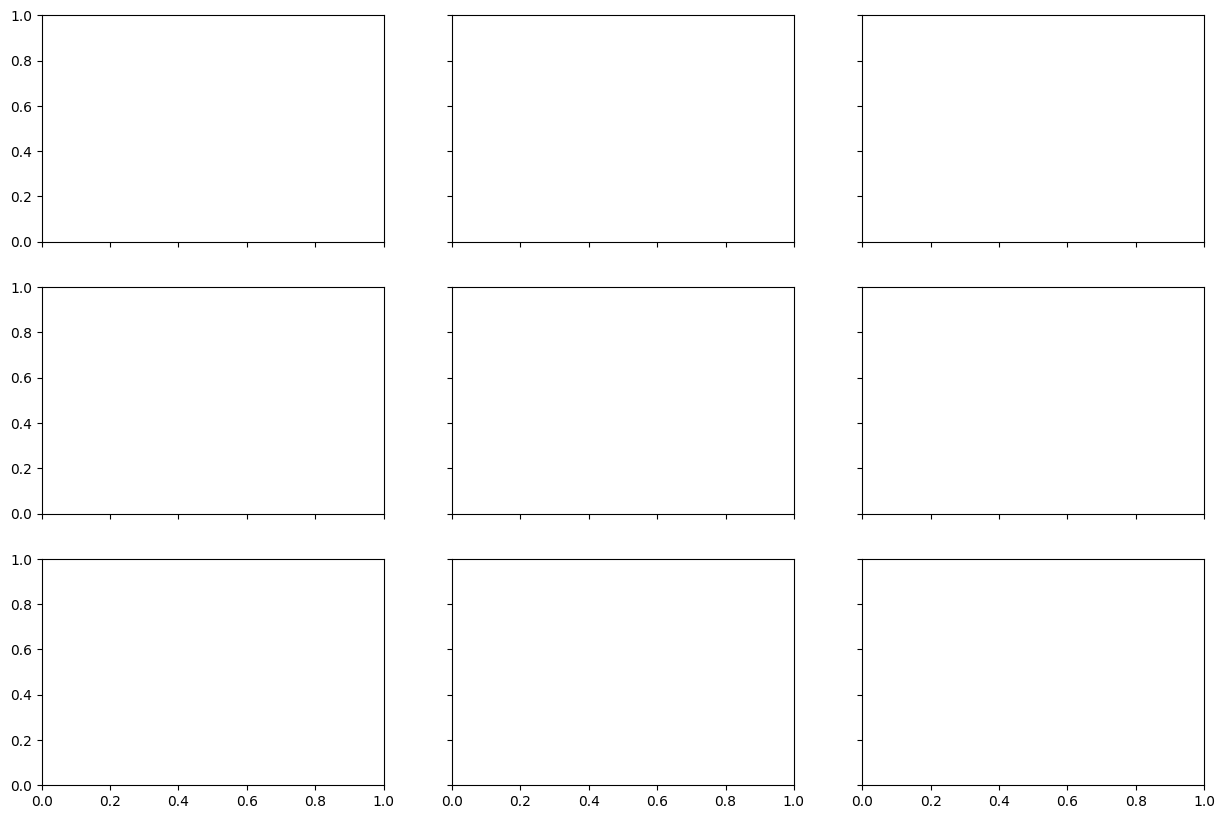

In [37]:
fig,axes = plt.subplots(3,3, figsize=(15,10), sharex = True, sharey = True)

# Flatten axes for easy iteration
axes = axes.flatten()

# Loop through each equipment
enumerate(df_machines['equipo'])
for i, equipo in enumerate(df_machines['equipo'][:len(axes)]):
    ax = axes[i]

    subset = train[train['equipo'] == equipo]
    subset = subset.sort_values('ds')
    


    subset_agg = subset.groupby('ds')['y'].sum().reset_index()
    #subset = subset.sort_values('ds')

    subset_agg['rolling'] = subset_agg['y'].rolling(window=7).mean()

    #ax.plot(subset['ds'],subset['y'], marker = 'o')
    ax.plot(subset_agg['ds'], subset_agg['rolling'])
    #ax.set_xticks(ax.get_xticks()[::5])
    #ax.tick_params(axis = 'x', rotation = 45)
    ax.set_title(equipo)
    ax.grid(True)

# Global labels
fig.suptitle ("Servicios por equipo", fontsize = 16)

# Optional: shared axix labels
for ax in axes[-3:]:
    ax.set_xlabel("ds") #first row

for ax in axes[::3]: # first column
    ax.set_ylabel("Numero de Servicios")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()




In [38]:
nvalidate = validation_halcyon.shape[0]
ntrain = train_halcyon.shape[0]
ntest = test_halcyon.shape[0]
print(ntrain)
print(nvalidate)
print(ntest)
print(train_halcyon)

874
292
292
               ds   equipo    y
9513   2025-03-25  HALCYON  4.0
2412   2023-01-26  HALCYON  4.0
11727  2025-11-26  HALCYON  5.0
9198   2025-02-18  HALCYON  4.0
8694   2024-12-24  HALCYON  4.0
...           ...      ...  ...
9585   2025-04-02  HALCYON  5.0
9855   2025-05-02  HALCYON  0.0
8946   2025-01-21  HALCYON  5.0
10764  2025-08-11  HALCYON  0.0
8190   2024-10-29  HALCYON  4.0

[874 rows x 3 columns]


In [39]:

m_halcyon = Prophet(
    # Seasonality settings
    yearly_seasonality=True, # Enable yearly patterns
    weekly_seasonality=True, # Enable weekly patterns
    daily_seasonality=False, # Disable daily (we have daily data but we want weekly patterns) 
    # Trend flexibility
    changepoint_prior_scale=0.05, # Lower = less flexible trend changes
    changepoint_range=0.8, # Proportion of data to consider for changepoints

    # Seasonality strength
    seasonality_prior_scale=10.0, # Higher = more flexible sasonality
    seasonality_mode='additive', # Additive seasonality (default)
    # Uncertainty intervals
    interval_width = 0.95, #95% confidence intervals
    mcmc_samples=0, # use MAP estimation (faster than MCMC)
)
m_halcyon.fit(train_halcyon)
future_halcyon = m_halcyon.make_future_dataframe(periods = nvalidate, freq = 'D')

In [40]:
print(future_halcyon.head(10))

          ds
0 2022-05-03
1 2022-05-05
2 2022-05-06
3 2022-05-07
4 2022-05-09
5 2022-05-11
6 2022-05-13
7 2022-05-14
8 2022-05-15
9 2022-05-17


In [41]:
forecast_halcyon = m_halcyon.predict(future_halcyon)
cols = ['yhat', 'yhat_lower', 'yhat_upper']
forecast_halcyon[cols] = forecast_halcyon[cols].clip(lower = 0)
forecast_halcyon[['ds','yhat', 'yhat_lower', 'yhat_upper', 
                  'trend', 'trend_lower', 'trend_upper']].tail()

,ds,yhat,yhat_lower,yhat_upper,trend,trend_lower,trend_upper
1161,2027-02-11,2.452499,0.0,4.866026,1.932830,1.914767,1.951297
1162,2027-02-12,2.212285,0.0,4.601528,1.931527,1.913362,1.950094
1163,2027-02-13,0.000000,0.0,0.356807,1.930223,1.911956,1.948864
1164,2027-02-14,0.000000,0.0,0.347970,1.928920,1.910551,1.947634
1165,2027-02-15,2.060865,0.0,4.534046,1.927616,1.909145,1.946412


In [42]:
size_forecast = forecast_halcyon.shape[0]
print(size_forecast)
print(forecast_halcyon.loc[:,'yhat'].shape[0])
print(df_halcyon.loc[:,'y'].iloc[:size_forecast].shape[0])
forecast_halcyon['ds'] = pd.to_datetime(forecast_halcyon['ds'])
df_halcyon['ds'] = pd.to_datetime(df_halcyon['ds'])
eval_halcyon = forecast_halcyon[['ds','yhat']].merge(df_halcyon[['ds','y']].iloc[:size_forecast],
                                                     on = 'ds',how = 'inner')
eval_halcyon['se'] = (eval_halcyon['yhat'] - eval_halcyon['y']) ** 2




1166
1166
1166


In [43]:

print("--HALCYON--\n")
print(f"SE = {eval_halcyon['se'].sum()}" )
print(f"MSE ={eval_halcyon['se'].mean()} ")
print(f"RMSE = {(eval_halcyon['se'].mean())**0.5}")


--HALCYON--

SE = 1032.5574384841173
MSE =1.4878349257696215 
RMSE = 1.2197683902157908


In [44]:
print(nvalidate)
print(eval_halcyon.shape[0])
print(eval_halcyon.shape[0]-292)
print(eval_halcyon.iloc[693])
eval_fhalcyon = eval_halcyon.iloc[401:693]
print(eval_fhalcyon.shape[0])


292
694
402
ds      2025-07-11 00:00:00
yhat               3.860552
y                       4.0
se                 0.019446
Name: 693, dtype: object
292


In [45]:
print("--HALCYON forecast--\n")
print(f"SE = {eval_fhalcyon['se'].sum()}" )
print(f"MSE ={eval_fhalcyon['se'].mean()} ")
print(f"RMSE = {(eval_fhalcyon['se'].mean())**0.5}")


--HALCYON forecast--

SE = 314.0909830599237
MSE =1.0756540515750812 
RMSE = 1.0371374313826887


# Add additional variable

In [46]:
fig_HALCYON = m_HALCYON.plot(forecast_HALCYON, include_legend = True)

NameError: name 'm_HALCYON' is not defined

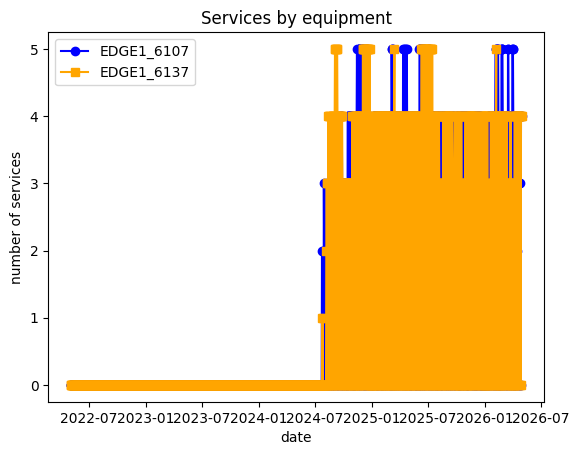

In [47]:
EDGE1_6107 = np.array(df_merged[df_merged['equipo']=="EDGE1_6107"]['y'])
EDGE2_6137 = np.array(df_merged[df_merged['equipo']=="EDGE2_6137"]['y'])
HALCYON = np.array(df_merged[df_merged['equipo']== "HALCYON"]['y'])
HALCYON3 = np.array(df_merged[df_merged['equipo']== "HALCYON3"]['y'])
HALCYON4 = np.array(df_merged[df_merged['equipo']=="HALCYON4"]['y'])
HALCYON5 = np.array(df_merged[df_merged['equipo']=="HALCYON5"]['y'])
SYNERGY = np.array(df_merged[df_merged['equipo'] =="SYNERGY"]['y'])
SYNERGY2 = np.array(df_merged[df_merged['equipo']=="SYNERGY2"]['y'])
SYNERGY3 = np.array(df_merged[df_merged['equipo']=="SYNERGY3"]['y'])
x = np.array(df_merged[df_merged['equipo'] == "SYNERGY3"]['ds'])

plt.plot(x, EDGE1_6107, label = "EDGE1_6107", color = 'blue', marker = 'o')
plt.plot(x, EDGE2_6137, label = "EDGE1_6137", color = 'orange', marker = 's')

plt.title('Services by equipment')
plt.xlabel('date')
plt.ylabel('number of services')
plt.legend()

# plt.figure(figsize = (8,5))


In [48]:
np.random.seed(42)
model = Prophet(yearly_seasonality=True, weekly_seasonality = False, daily_seasonality = False)

In [49]:
model.fit(df_merged)

In [50]:
#Forecast next 12 months beyond
future = model.make_future_dataframe(periods = 14, freq = "D")

In [51]:
# Generate Forecast
forecast= model.predict(future),

In [52]:
print(forecast)

(             ds     trend  yhat_lower  yhat_upper  trend_lower  trend_upper  \
0    2022-05-03  1.443343   -1.542289    4.167804     1.443343     1.443343   
1    2022-05-04  1.443634   -1.597002    4.511682     1.443634     1.443634   
2    2022-05-05  1.443926   -1.612030    4.522814     1.443926     1.443926   
3    2022-05-06  1.444217   -1.403407    4.281259     1.444217     1.444217   
4    2022-05-07  1.444508   -1.438555    4.425789     1.444508     1.444508   
...         ...       ...         ...         ...          ...          ...   
1467 2026-05-09  2.105707   -0.754385    4.968402     2.105707     2.105707   
1468 2026-05-10  2.104896   -0.838256    5.071219     2.104896     2.104896   
1469 2026-05-11  2.104085   -0.812755    5.057181     2.104084     2.104085   
1470 2026-05-12  2.103274   -0.745574    4.989464     2.103245     2.103274   
1471 2026-05-13  2.102463   -0.714842    4.907533     2.102404     2.102481   

      additive_terms  additive_terms_lower  additi